Experiment with random pose and A sort of retrieval

In [ ]:
import sys
sys.path.append("/Experiments/riccardop02")

from dotenv import load_dotenv
import os

os.environ["HF_HOME"] = "/Experiments/riccardop02/huggingface"


import torch
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt
from transformers import AutoModel, AutoImageProcessor

from JEPA.Essential.path import RENDERS
import plotly.io as pio #; pio.renderers.default = "notebook"

device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

MODEL_NAME = "facebook/dinov3-vitb16-pretrain-lvd1689m"
load_dotenv()
hf_token = os.getenv("HF_TOKEN")



processor = AutoImageProcessor.from_pretrained(MODEL_NAME)
model = AutoModel.from_pretrained(MODEL_NAME, token= hf_token).to(device).eval()

# spegniamo i gradienti: facciamo solo inferenza, encoder frozen
for p in model.parameters():
    p.requires_grad_(False)

n_params = sum(p.numel() for p in model.parameters())
print(f"{MODEL_NAME} caricato — {n_params/1e6:.1f}M parametri")
print("patch size:", model.config.patch_size, "| hidden dim:", model.config.hidden_size)

device: cuda


Loading weights: 100%|██████████| 211/211 [00:00<00:00, 8226.65it/s]

facebook/dinov3-vitb16-pretrain-lvd1689m caricato — 85.7M parametri
patch size: 16 | hidden dim: 768


In [ ]:
import torch.nn.functional as F

@torch.no_grad()
def extract_features2(img, layers=[-1], token="pool", grid=2,
                     norm_mode="global", normalize=True):
    """
    token="pool" -> spatial pooling su griglia grid x grid (default 2x2)
    norm_mode:
        "global" -> L2 sul descrittore finale concatenato
        "cell"   -> L2 su ogni cella PRIMA di concatenare
    """
    inputs = processor(images=img, return_tensors="pt").to(device)
    hs = model(**inputs, output_hidden_states=True).hidden_states

    parts = []
    for L in layers:
        h = hs[L][0]                              # (n_token, 768)
        if token == "cls":
            v = h[0]
        elif token == "ptc":
            v = h[5:].flatten()
        elif token == "pool":
            P = h[5:]                             # (256, 768)
            side = int(P.shape[0] ** 0.5)         # 16
            g = P.reshape(side, side, -1)         # (16, 16, 768)
            step = side // grid                   # quante patch per cella
            cells = []
            for r in range(grid):
                for c in range(grid):
                    cell = g[r*step:(r+1)*step, c*step:(c+1)*step, :].mean(dim=(0, 1))
                    if norm_mode == "cell":
                        cell = F.normalize(cell, dim=-1)
                    cells.append(cell)
            v = torch.cat(cells)                  # (grid*grid*768,)

        elif token == "hybrid":
            cls = F.normalize(h[0], dim=-1)                     # texture/semantica
            P = h[5:]
            side = int(P.shape[0] ** 0.5)
            gr = P.reshape(side, side, -1)
            step = side // grid
            cells = [gr[r*step:(r+1)*step, c*step:(c+1)*step, :].mean(dim=(0, 1))
                     for r in range(grid) for c in range(grid)]
            pool = F.normalize(torch.cat(cells), dim=-1)         # geometria
            v = torch.cat([cls, pool])                           # texture + forma

        else:
            raise ValueError(token)

        if normalize and token not in ("hybrid") and not (token == "pool" and norm_mode == "cell"):
            v = F.normalize(v, dim=-1)
        parts.append(v)
    return torch.cat(parts, dim=-1)

# verifica dimensioni
for gr in [1, 2, 3, 4]:
    d = extract_features2(Image.new("RGB", (224,224), (128,128,128)),
                         token="pool", grid=gr).shape[0]
    print(f"grid {gr}x{gr} -> {d} dim")

grid 1x1 -> 768 dim
grid 2x2 -> 3072 dim
grid 3x3 -> 6912 dim
grid 4x4 -> 12288 dim


In [ ]:
dummy = Image.new("RGB", (224, 224), (128, 128, 128))
emb = extract_features2(dummy, layers=[-1], token="pool")
print("Dimension Descriptor:", emb.shape)       

Dimension Descriptor: torch.Size([3072])


Calcolo embedding di 800 immagini...


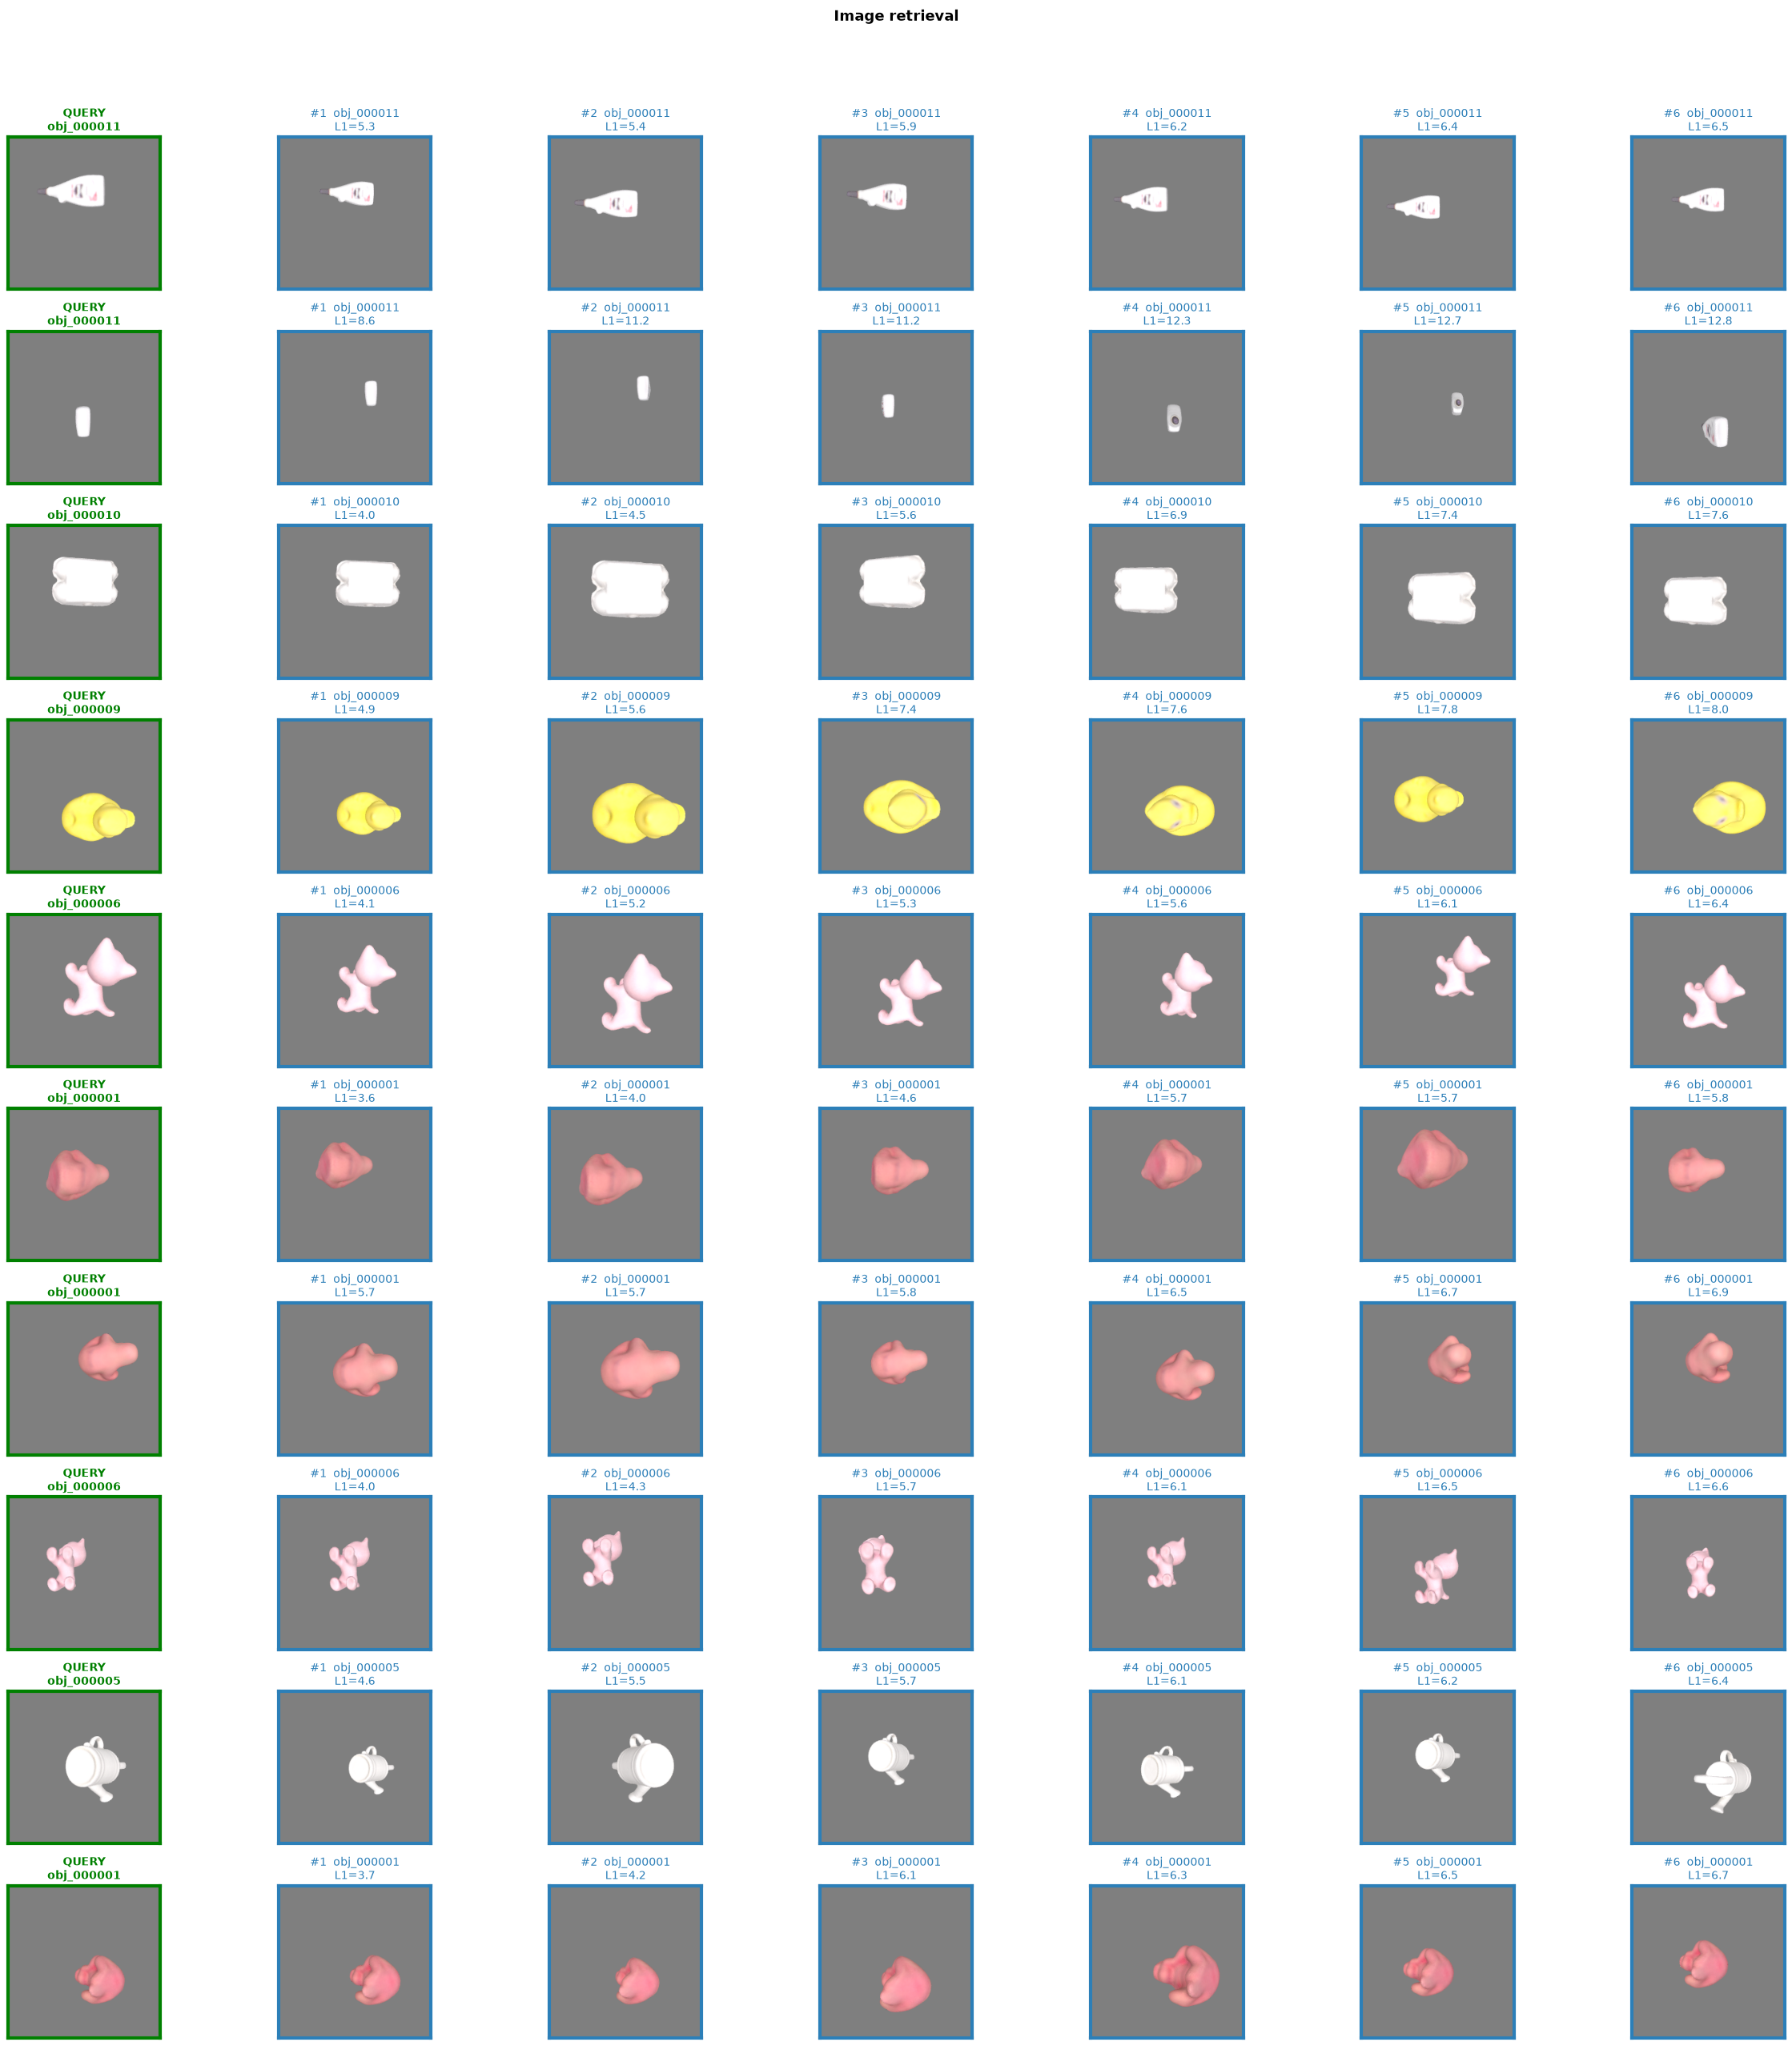

In [ ]:

DATASET = "lmo"          
TOKEN   = "pool"
GRID    = 2
SEED    = 0

# PARAM
NUM_QUERIES = 10  # Number of test
TOP_K       = 6  # Instance of comparison

df = pd.read_csv(RENDERS / DATASET / "gt_poses.csv").reset_index(drop=True)

# Compute the representation for all the image generated from the script
print(f"Calcolo embedding di {len(df)} immagini...")
gallery = []
for i in range(len(df)):
    e = extract_features2(Image.open(RENDERS / df.iloc[i]["image"]).convert("RGB"),
                          token=TOKEN, grid=GRID)
    gallery.append(e)
gallery = torch.stack(gallery)        # (N, D)

# Extract NUM_QUERIES test
rng = np.random.default_rng(SEED)
queries = rng.choice(len(df), size=NUM_QUERIES, replace=False)

#PLOT
fig, axes = plt.subplots(NUM_QUERIES, TOP_K + 1, figsize=(3.5 * (TOP_K + 1), 2.5 * NUM_QUERIES))

# Case 1 test
if NUM_QUERIES == 1:
    axes = np.expand_dims(axes, axis=0)

for r, q in enumerate(queries):
    # L1 with all
    d = torch.abs(gallery - gallery[q]).sum(dim=1)
    d[q] = float("inf")               # Escludi se stessa
    
    # take the best
    top = torch.argsort(d)[:TOP_K].cpu().numpy()


    qrow = df.iloc[q]
    axes[r, 0].imshow(Image.open(RENDERS / qrow["image"]).convert("RGB"))
    axes[r, 0].set_title(f"QUERY\n{qrow['object']}", fontsize=10, color="green", fontweight="bold")
    for s in axes[r, 0].spines.values(): 
        s.set_color("green")
        s.set_linewidth(3)
    axes[r, 0].set_xticks([])
    axes[r, 0].set_yticks([])

    for k, idx in enumerate(top):
        row = df.iloc[idx]
        
        same = (row["object"] == qrow["object"])
        col = "#2c7fb8" if same else "#d95f0e"
        
        axes[r, k+1].imshow(Image.open(RENDERS / row["image"]).convert("RGB"))
        axes[r, k+1].set_title(f"#{k+1}  {row['object']}\nL1={d[idx]:.1f}", fontsize=10, color=col)
        for s in axes[r, k+1].spines.values(): 
            s.set_color(col)
            s.set_linewidth(3)
        axes[r, k+1].set_xticks([])
        axes[r, k+1].set_yticks([])

# Titolo generale
plt.suptitle(
    f"Image retrieval\n", 
    y=1.02, fontsize=13, fontweight="bold"
)

plt.tight_layout()
plt.show()

# SIM TO REAL -- GAP (If we move to occlusion and real scene it reduces performance????)


In [ ]:
import sys
import json
import numpy as np
from PIL import Image

sys.path.append("/Experiments/riccardop02")
from JEPA.Essential.path import scene_gt, scene_camera, get_registered_detection, rgb_file, mask_visib, detection_file, model_file

METHOD = "cnos"
DATASET_NAME = "ycbv"
SPLIT = "test"

# Get the detection and open the file
try:
    det_path = get_registered_detection(METHOD, DATASET_NAME, SPLIT)
except KeyError as e:
    print(f"[ERROR] {e}")
    sys.exit(1)

with open(det_path, 'r') as f:
    dets = json.load(f)

# Take the first detection (and obtain scene_id and image_id)
d0 = dets[0]
sid, iid = d0["scene_id"], d0["image_id"]
image_id_str = str(iid)

print(f"--- {METHOD.upper()} Correctly read data from CNOS ---")
print({k: d0[k] for k in ["scene_id", "image_id", "category_id", "bbox", "score"]})

gt_path = scene_gt(DATASET_NAME, sid, split=SPLIT)
cam_path = scene_camera(DATASET_NAME, sid, split=SPLIT)

with open(gt_path, 'r') as f:
    gt = json.load(f)
with open(cam_path, 'r') as f:
    cam = json.load(f)

# Take the first and watch if the data are correctly manage
if image_id_str in gt:
    gt_obj_ids = [o["obj_id"] for o in gt[image_id_str]]
    pred_id = d0['category_id']
    
    print(f"GT objects : {gt_obj_ids}")
    print(f"Prediction : {pred_id}")
    print(f"Match      : {pred_id in gt_obj_ids}")
    print(f"K:\n{np.array(cam[image_id_str]['cam_K']).reshape(3,3)}")
else:
    print(f"[ERROR] image_id {iid} not found in GT.")

--- CNOS Correctly read data from CNOS ---
{'scene_id': 48, 'image_id': 1024, 'category_id': 1, 'bbox': [339, 170, 96, 133], 'score': 0.7473174929618835}
GT objects : [1, 6, 14, 19, 20]
Prediction : 1
Match      : True
K:
[[1.066778e+03 0.000000e+00 3.129869e+02]
 [0.000000e+00 1.067487e+03 2.413109e+02]
 [0.000000e+00 0.000000e+00 1.000000e+00]]


In [ ]:
import pycocotools.mask as coco_mask

METHOD = "cnos"
DATASET_NAME = "ycbv"
SPLIT = "test"

# Function to take K, GT Pose and rle conversion

def load_real(scene_id: int, image_id: int, dataset=DATASET_NAME, split=SPLIT):
    return Image.open(rgb_file(dataset, scene_id, image_id, split=split)).convert("RGB")

def load_K(scene_id: int, image_id: int, dataset=DATASET_NAME, split=SPLIT):
    with open(scene_camera(dataset, scene_id, split=split), 'r') as f:
        cam = json.load(f)
    return np.array(cam[str(image_id)]["cam_K"]).reshape(3, 3)

def load_gt_poses(scene_id: int, image_id: int, dataset=DATASET_NAME, split=SPLIT):
    with open(scene_gt(dataset, scene_id, split=split), 'r') as f:
        gt = json.load(f)
    
    out = []
    for o in gt[str(image_id)]:
        R = np.array(o["cam_R_m2c"]).reshape(3, 3)
        t = np.array(o["cam_t_m2c"]).reshape(3)
        out.append((o["obj_id"], R, t))
    return out

def rle_to_mask(seg: dict):
    if isinstance(seg["counts"], list):
        seg = coco_mask.frPyObjects(seg, seg["size"][0], seg["size"][1])
    return coco_mask.decode(seg).astype(bool)

def load_gt_mask(scene_id: int, image_id: int, obj_idx: int, dataset=DATASET_NAME, split=SPLIT):
    m = Image.open(mask_visib(dataset, scene_id, image_id, obj_idx, split=split))
    return np.array(m).astype(bool)


# Try with the first image
try:
    det_path = get_registered_detection(METHOD, DATASET_NAME, SPLIT)
except KeyError as e:
    print(f"[ERROR] {e}")
    sys.exit(1)

with open(det_path, 'r') as f:
    dets = json.load(f)

d0 = dets[0]
sid, iid = d0["scene_id"], d0["image_id"]

img = load_real(sid, iid)
K = load_K(sid, iid)
poses = load_gt_poses(sid, iid)

print(f"--- {METHOD.upper()} [0] ---")
print(f"Image Size : {img.size}")
print(f"K Focal X  : {K[0,0]:.0f}")
print(f"GT Objects : {[p[0] for p in poses]}")

mask_cnos = rle_to_mask(d0["segmentation"])
print(f"CNOS Mask  : {mask_cnos.shape} (Active pixels: {mask_cnos.sum()})")

--- CNOS [0] ---
Image Size : (640, 480)
K Focal X  : 1067
GT Objects : [1, 6, 14, 19, 20]
CNOS Mask  : (480, 640) (Active pixels: 11008)


[INFO] Rendering obj_id 2 at Ground Truth pose...


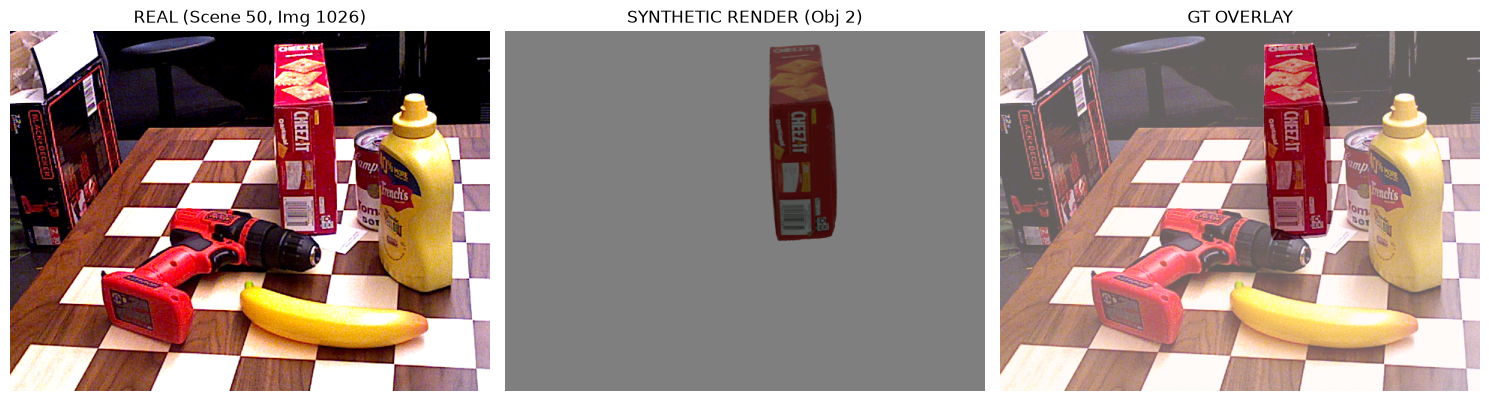

In [ ]:
import os
os.environ["PYOPENGL_PLATFORM"] = "egl"
import trimesh
import pyrender
import matplotlib.pyplot as plt

IMG_W, IMG_H = 640, 480
BG_GRAY = 0.5
_MESH_CACHE = {}

# RENDER POSE

try:
    _RENDERER = pyrender.OffscreenRenderer(IMG_W, IMG_H)
except Exception as e:
    print(f"[WARNING] Failed to initialize EGL renderer. Rendering bypassed: {e}")
    _RENDERER = None

def _intrinsics_camera(K: np.ndarray, znear=1.0, zfar=10000.0):
    fx, fy = K[0,0], K[1,1]
    cx, cy = K[0,2], K[1,2]
    return pyrender.IntrinsicsCamera(fx=fx, fy=fy, cx=cx, cy=cy, znear=znear, zfar=zfar)

def _add_raymond_lights(scene: pyrender.Scene):
    thetas = np.pi * np.array([1/6, 1/6, 1/6])
    phis = np.pi * np.array([0, 2/3, 4/3])
    
    for th, ph in zip(thetas, phis):
        z = np.array([np.sin(th)*np.cos(ph), np.sin(th)*np.sin(ph), np.cos(th)])
        z /= np.linalg.norm(z)
        x = np.array([-z[1], z[0], 0.0])
        x = x / np.linalg.norm(x) if np.linalg.norm(x) > 1e-8 else np.array([1., 0, 0])
        y = np.cross(z, x)
        
        pose = np.eye(4)
        pose[:3, :3] = np.c_[x, y, z]
        scene.add(pyrender.DirectionalLight(color=np.ones(3), intensity=2.5), pose=pose)

def _get_mesh(obj_id: int, dataset=DATASET_NAME):
    if obj_id not in _MESH_CACHE:
        tm = trimesh.load(model_file(dataset, obj_id), force="mesh")
        _MESH_CACHE[obj_id] = pyrender.Mesh.from_trimesh(tm, smooth=False)
    return _MESH_CACHE[obj_id]

# Function that render the cad (obj_id) into a predefined pose
def render_at_pose(obj_id: int, R: np.ndarray, t: np.ndarray, K: np.ndarray, dataset=DATASET_NAME):
    if _RENDERER is None:
        return Image.new('RGB', (IMG_W, IMG_H), (0, 0, 0)), np.zeros((IMG_H, IMG_W), dtype=bool)

    # Prepare Backgroun, light and import object
    scene = pyrender.Scene(bg_color=np.array([BG_GRAY]*3), ambient_light=np.array([0.35]*3))
    scene.add(_get_mesh(obj_id, dataset), pose=np.eye(4))
    _add_raymond_lights(scene)

    # Set the predefined pose of the objectt 
    M = np.eye(4)
    M[:3, :3] = R
    M[:3, 3] = t
    
    cv_to_gl = np.diag([1, -1, -1, 1]).astype(float)        # To invert axis Y,Z
    cam_pose = np.linalg.inv(cv_to_gl @ M)                  

    cam = _intrinsics_camera(K)
    scene.add(cam, pose=cam_pose)


    # Render the pose
    try:
        color, depth = _RENDERER.render(scene)
        mask = depth > 0
        return Image.fromarray(color), mask
    except Exception as e:
        print(f"[WARNING] EGL Render Context Failed. Bypassing visualization: {e}")
        return Image.new('RGB', (IMG_W, IMG_H), (0, 0, 0)), np.zeros((IMG_H, IMG_W), dtype=bool)


# See if its well done
if __name__ == "__main__":
    if 'poses' in locals() and len(poses) > 0:
        obj_id, R_gt, t_gt = poses[0]
        
        print(f"[INFO] Rendering obj_id {obj_id} at Ground Truth pose...")
        rend_img, rend_mask = render_at_pose(obj_id, R_gt, t_gt, K)

        fig, ax = plt.subplots(1, 3, figsize=(15, 4))
        
        ax[0].imshow(img)
        ax[0].set_title(f"REAL (Scene {sid}, Img {iid})")
        ax[0].axis("off")
        
        ax[1].imshow(rend_img)
        ax[1].set_title(f"SYNTHETIC RENDER (Obj {obj_id})")
        ax[1].axis("off")
        
        ax[2].imshow(img)
        if rend_mask.any():
            ax[2].imshow(rend_mask, alpha=0.4, cmap="Reds")
        ax[2].set_title("GT OVERLAY")
        ax[2].axis("off")
        
        plt.tight_layout()
        plt.show()
    else:
        print("[WARNING] No Ground Truth poses found for this image.")

[WARNING] Predicted category 1 not found in GT list. Skipping GT crop.


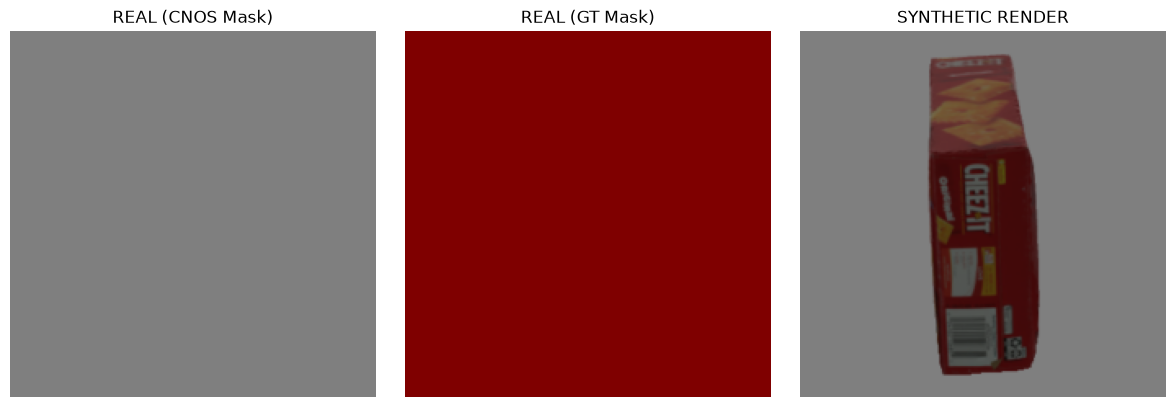

In [ ]:
#Function that crop
def crop_and_mask(
    img: Image.Image, 
    mask: np.ndarray, 
    bbox: list = None, 
    out_size: int = 224, 
    pad: float = 0.15, 
    bg: float = 0.5
) -> Image.Image:
    
    arr = np.array(img).astype(np.float32)
    m = mask.astype(bool)

    arr[~m] = bg * 255.0

    if bbox is not None:
        x, y, w, h = bbox
    else:
        ys, xs = np.where(m)
        if len(ys) == 0 or len(xs) == 0:
            return Image.new('RGB', (out_size, out_size), int(bg * 255))
        x, y = xs.min(), ys.min()
        w, h = xs.max() - x, ys.max() - y

    # find the center
    cx, cy = x + w / 2.0, y + h / 2.0
    side = max(w, h) * (1.0 + pad)
    
    x0, y0 = int(cx - side / 2.0), int(cy - side / 2.0)
    x1, y1 = int(cx + side / 2.0), int(cy + side / 2.0)

    H, W = arr.shape[:2]
    canvas = np.full((y1 - y0, x1 - x0, 3), bg * 255.0, dtype=np.float32)
    
    sx0, sy0 = max(0, x0), max(0, y0)
    sx1, sy1 = min(W, x1), min(H, y1)
    
    canvas_y0, canvas_y1 = sy0 - y0, sy1 - y0
    canvas_x0, canvas_x1 = sx0 - x0, sx1 - x0
    
    if canvas_y1 > canvas_y0 and canvas_x1 > canvas_x0:
        canvas[canvas_y0:canvas_y1, canvas_x0:canvas_x1] = arr[sy0:sy1, sx0:sx1]

    # return a center image
    return Image.fromarray(canvas.astype(np.uint8)).resize((out_size, out_size), Image.Resampling.BILINEAR)


## MOSTRA IL CROP PER TUTTE LE IMMAGINI
if __name__ == "__main__":
    real_cnos = crop_and_mask(img, mask_cnos, bbox=d0["bbox"])
    
    try:
        obj_idx = gt_obj_ids.index(pred_id)
        mask_gt = load_gt_mask(sid, iid, obj_idx)
        real_gt = crop_and_mask(img, mask_gt)
    except ValueError:
        print(f"[WARNING] Predicted category {pred_id} not found in GT list. Skipping GT crop.")
        real_gt = Image.new('RGB', (224, 224), int(BG_GRAY * 255))

    if 'rend_img' in locals() and 'rend_mask' in locals():
        rend_crop = crop_and_mask(rend_img, rend_mask)
    else:
        rend_crop = Image.new('RGB', (224, 224), int(BG_GRAY * 255))

    fig, ax = plt.subplots(1, 3, figsize=(12, 4))
    
    ax[0].imshow(real_cnos)
    ax[0].set_title("REAL (CNOS Mask)")
    ax[0].axis("off")
    
    ax[1].imshow(real_gt)
    ax[1].set_title("REAL (GT Mask)")
    ax[1].axis("off")
    
    ax[2].imshow(rend_crop)
    ax[2].set_title("SYNTHETIC RENDER")
    ax[2].axis("off")
    
    plt.tight_layout()
    plt.show()

[WARNING] EGL Render Context Failed. Bypassing visualization: GLError(
	err = 12289,
	baseOperation = eglMakeCurrent,
	cArguments = (
	),
	result = 0
)
[WARNING] EGL Render Context Failed. Bypassing visualization: GLError(
	err = 12289,
	baseOperation = eglMakeCurrent,
	cArguments = (
	),
	result = 0
)
[WARNING] EGL Render Context Failed. Bypassing visualization: GLError(
	err = 12289,
	baseOperation = eglMakeCurrent,
	cArguments = (
	),
	result = 0
)
[WARNING] EGL Render Context Failed. Bypassing visualization: GLError(
	err = 12289,
	baseOperation = eglMakeCurrent,
	cArguments = (
	),
	result = 0
)
[WARNING] EGL Render Context Failed. Bypassing visualization: GLError(
	err = 12289,
	baseOperation = eglMakeCurrent,
	cArguments = (
	),
	result = 0
)
[WARNING] EGL Render Context Failed. Bypassing visualization: GLError(
	err = 12289,
	baseOperation = eglMakeCurrent,
	cArguments = (
	),
	result = 0
)
[WARNING] EGL Render Context Failed. Bypassing visualization: GLError(
	err = 12289,
	ba

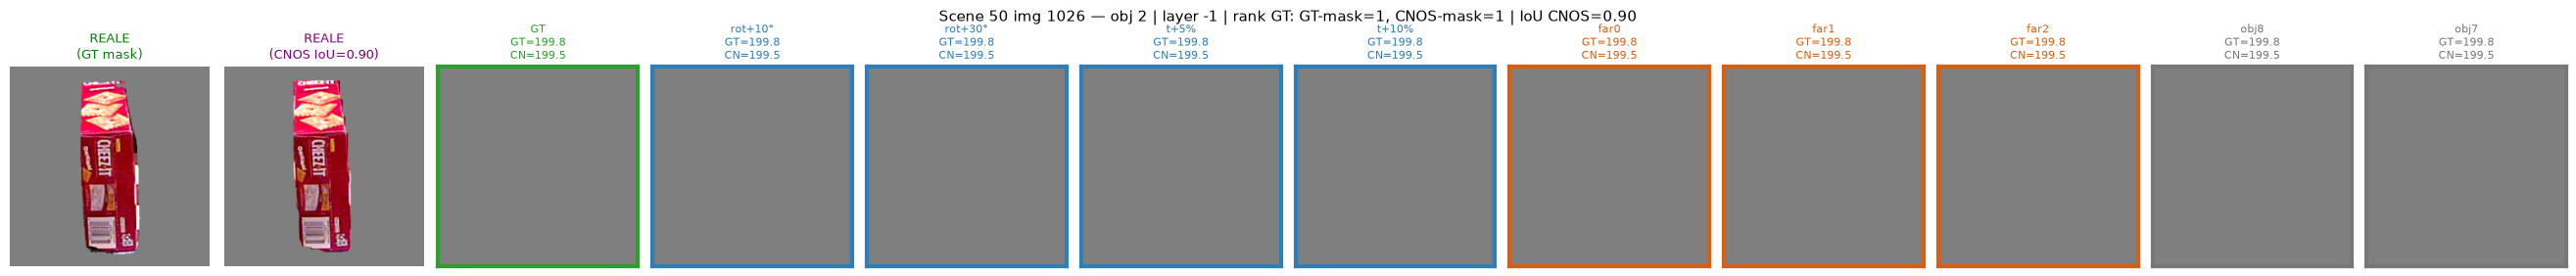

[WARNING] EGL Render Context Failed. Bypassing visualization: GLError(
	err = 12289,
	baseOperation = eglMakeCurrent,
	cArguments = (
	),
	result = 0
)
[WARNING] EGL Render Context Failed. Bypassing visualization: GLError(
	err = 12289,
	baseOperation = eglMakeCurrent,
	cArguments = (
	),
	result = 0
)
[WARNING] EGL Render Context Failed. Bypassing visualization: GLError(
	err = 12289,
	baseOperation = eglMakeCurrent,
	cArguments = (
	),
	result = 0
)
[WARNING] EGL Render Context Failed. Bypassing visualization: GLError(
	err = 12289,
	baseOperation = eglMakeCurrent,
	cArguments = (
	),
	result = 0
)
[WARNING] EGL Render Context Failed. Bypassing visualization: GLError(
	err = 12289,
	baseOperation = eglMakeCurrent,
	cArguments = (
	),
	result = 0
)
[WARNING] EGL Render Context Failed. Bypassing visualization: GLError(
	err = 12289,
	baseOperation = eglMakeCurrent,
	cArguments = (
	),
	result = 0
)
[WARNING] EGL Render Context Failed. Bypassing visualization: GLError(
	err = 12289,
	ba

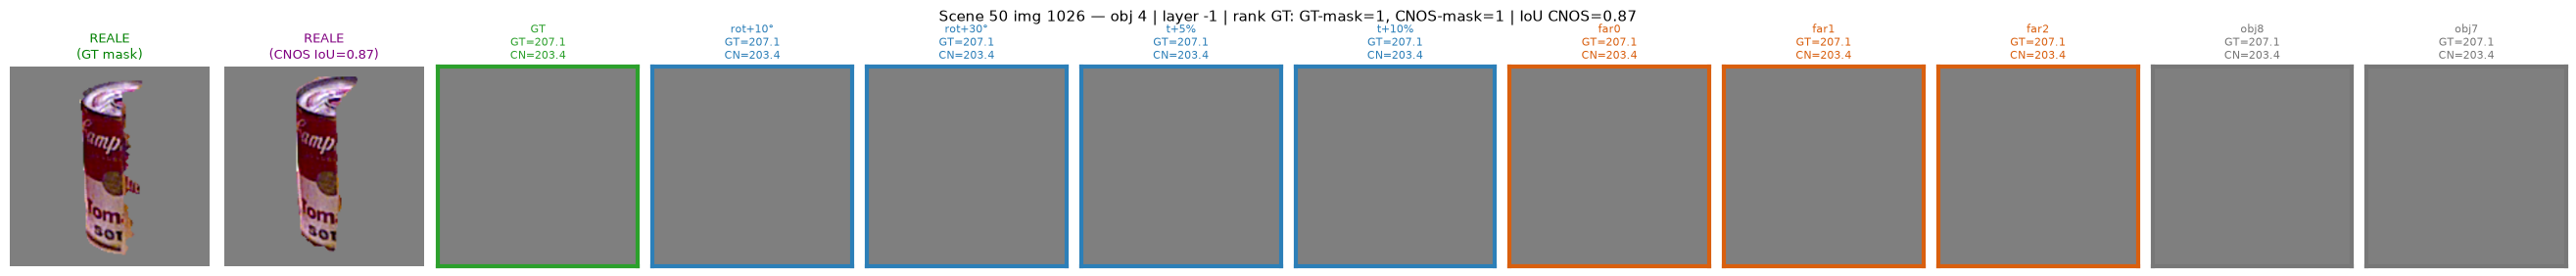

[WARNING] EGL Render Context Failed. Bypassing visualization: GLError(
	err = 12289,
	baseOperation = eglMakeCurrent,
	cArguments = (
	),
	result = 0
)
[WARNING] EGL Render Context Failed. Bypassing visualization: GLError(
	err = 12289,
	baseOperation = eglMakeCurrent,
	cArguments = (
	),
	result = 0
)
[WARNING] EGL Render Context Failed. Bypassing visualization: GLError(
	err = 12289,
	baseOperation = eglMakeCurrent,
	cArguments = (
	),
	result = 0
)
[WARNING] EGL Render Context Failed. Bypassing visualization: GLError(
	err = 12289,
	baseOperation = eglMakeCurrent,
	cArguments = (
	),
	result = 0
)
[WARNING] EGL Render Context Failed. Bypassing visualization: GLError(
	err = 12289,
	baseOperation = eglMakeCurrent,
	cArguments = (
	),
	result = 0
)
[WARNING] EGL Render Context Failed. Bypassing visualization: GLError(
	err = 12289,
	baseOperation = eglMakeCurrent,
	cArguments = (
	),
	result = 0
)
[WARNING] EGL Render Context Failed. Bypassing visualization: GLError(
	err = 12289,
	ba

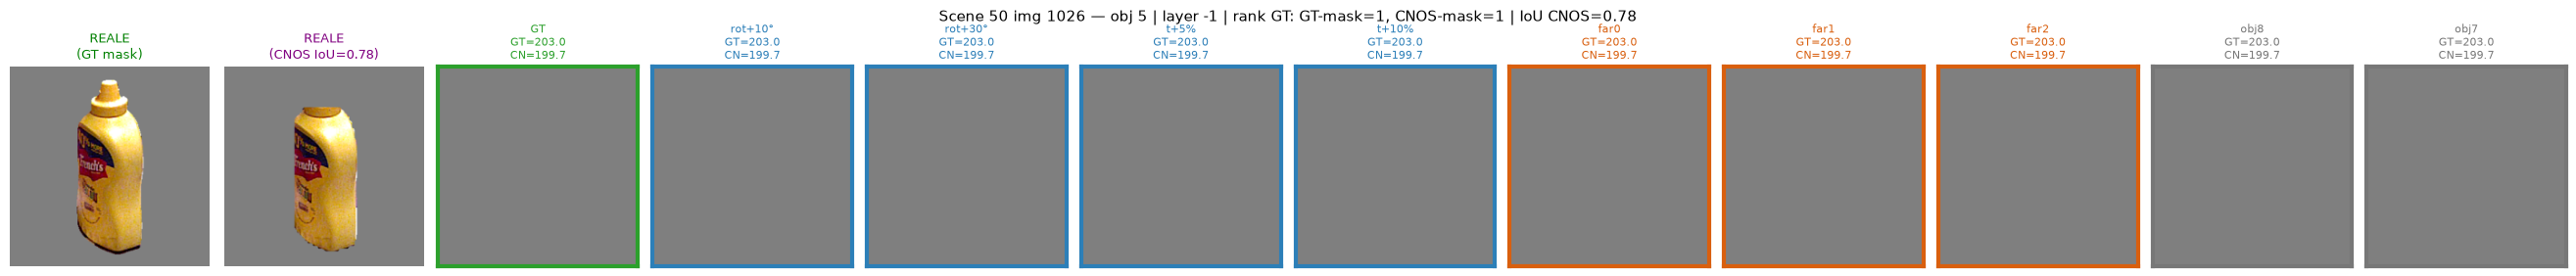

KeyboardInterrupt: 

In [ ]:
import numpy as np, torch, matplotlib.pyplot as plt
from scipy.spatial.transform import Rotation
from scipy.ndimage import binary_erosion
import pycocotools.mask as coco_mask

TOKEN, GRID, LAYER = "ptc", 2, [-1]   

# reconstruct mask
def rle_to_mask(seg):
    rle = seg
    if isinstance(rle["counts"], list):
        rle = coco_mask.frPyObjects(rle, seg["size"][0], seg["size"][1])
    return coco_mask.decode(rle).astype(bool)

def _iou(a, b):
    ax, ay, aw, ah = a; bx, by, bw, bh = b
    x0, y0 = max(ax,bx), max(ay,by)
    x1, y1 = min(ax+aw, bx+bw), min(ay+ah, by+bh)
    inter = max(0, x1-x0) * max(0, y1-y0)
    union = aw*ah + bw*bh - inter
    return inter/union if union > 0 else 0.0

# Find the best CNOS mask (that is similar to the gt)
def best_cnos_for_gt(img_dets, cat, gt_bbox):
    
    cands = [d for d in img_dets if d["category_id"] == cat and d.get("segmentation")]
    if not cands:
        return None, 0.0
    best = max(cands, key=lambda d: _iou(d["bbox"], gt_bbox))
    return best, _iou(best["bbox"], gt_bbox)

def perturb_pose(R, t, deg_rot=0, trans_frac=0.0):
    axis = np.random.randn(3); axis /= np.linalg.norm(axis)
    dR = Rotation.from_rotvec(np.deg2rad(deg_rot) * axis).as_matrix()
    dt = np.zeros(3)
    if trans_frac > 0:
        dt = np.random.randn(3); dt /= np.linalg.norm(dt); dt *= trans_frac * np.linalg.norm(t)
    return dR @ R, t + dt

def aligned_crop(img_real, mask_real, img_rend, mask_rend, out_size=224, pad=0.15, bg=0.5, erode=2):
    mr = binary_erosion(mask_real, iterations=erode)
    mg = binary_erosion(mask_rend, iterations=erode)
    ys, xs = np.where(mr)
    bbox = (xs.min(), ys.min(), xs.max()-xs.min(), ys.max()-ys.min())
    real_crop = crop_and_mask(img_real, mr, bbox=bbox, out_size=out_size, pad=pad, bg=bg)
    rend_crop = crop_and_mask(img_rend, mg, bbox=bbox, out_size=out_size, pad=pad, bg=bg)
    return real_crop, rend_crop, bbox

# ── esperimento ──────────────────────────────────────────────────────────
test_images = [(50, 1026), (58, 553), (54, 1580), (56, 1054), (59, 908)]
all_obj_ids = sorted({d["category_id"] for d in dets})

# show the images and its relative score with CNOS MASK and GT MASK
for sid, iid in test_images:
    img = load_real(sid, iid)
    K   = load_K(sid, iid)
    poses = load_gt_poses(sid, iid)
    gt_obj_ids = [p[0] for p in poses]
    img_dets = [d for d in dets if d["scene_id"]==sid and d["image_id"]==iid]

    for cat in gt_obj_ids:                      # itero sugli oggetti GT, non sulle detection
        obj_idx = gt_obj_ids.index(cat)
        mask_gt = load_gt_mask(sid, iid, obj_idx)
        R_gt, t_gt = next((R,t) for (oid,R,t) in poses if oid==cat)

        # Render real image pose (should the best)
        rend_gt, m_gt = render_at_pose(cat, R_gt, t_gt, K)
        real_crop, gt_crop, bbox_gt = aligned_crop(img, mask_gt, rend_gt, m_gt)
        e_real_gt = extract_features2(real_crop, layers=LAYER, token=TOKEN, grid=GRID)

        # CNOS Mask (to show if the missing piece destroy the result)
        ys, xs = np.where(mask_gt)
        gt_bbox = (xs.min(), ys.min(), xs.max()-xs.min(), ys.max()-ys.min())
        best_det, iou_gt = best_cnos_for_gt(img_dets, cat, gt_bbox)
        if best_det is not None:
            mask_cnos = rle_to_mask(best_det["segmentation"])
            real_crop_cnos = crop_and_mask(img, mask_cnos, bbox=bbox_gt)
            e_real_cnos = extract_features2(real_crop_cnos, layers=LAYER, token=TOKEN, grid=GRID)
        else:
            real_crop_cnos, e_real_cnos = None, None

        # Random transformation applied
        rows = [("GT", "gt", gt_crop)]
        for dg in (10, 30):
            Rp, tp = perturb_pose(R_gt, t_gt, deg_rot=dg)
            r, m = render_at_pose(cat, Rp, tp, K)
            rows.append((f"rot+{dg}°", "near", crop_and_mask(r, m, bbox=bbox_gt)))
        for frac in (0.05, 0.10):
            Rp, tp = perturb_pose(R_gt, t_gt, trans_frac=frac)
            r, m = render_at_pose(cat, Rp, tp, K)
            rows.append((f"t+{int(frac*100)}%", "near", crop_and_mask(r, m, bbox=bbox_gt)))
        rng = np.random.default_rng(0)
        for k in range(3):
            Rr = Rotation.random(random_state=rng.integers(1e6)).as_matrix()
            r, m = render_at_pose(cat, Rr, t_gt, K)
            rows.append((f"far{k}", "far", crop_and_mask(r, m, bbox=bbox_gt)))

        # append different objects
        others = [o for o in all_obj_ids if o != cat]
        for oid in rng.choice(others, size=min(2, len(others)), replace=False):
            Rr = Rotation.random(random_state=rng.integers(1e6)).as_matrix()
            r, m = render_at_pose(int(oid), Rr, t_gt, K)
            rows.append((f"obj{oid}", "other", crop_and_mask(r, m, bbox=bbox_gt)))

        # compute the score for each rows (that means for each object in the scene)
        scored = []
        for label, kind, im in rows:
            e = extract_features2(im, token=TOKEN, layers=LAYER, grid=GRID)
            l1_gt   = torch.abs(e_real_gt - e).sum().item()
            l1_cnos = torch.abs(e_real_cnos - e).sum().item() if e_real_cnos is not None else float("nan")
            scored.append((label, kind, l1_gt, l1_cnos, im))
        scored.sort(key=lambda x: x[2])

        rank_gt = [s[0] for s in scored].index("GT") + 1
        rank_cnos = ([s[0] for s in sorted(scored, key=lambda x: x[3])].index("GT") + 1
                     if e_real_cnos is not None else None)

        # PLOT
        ncol = len(scored) + (2 if e_real_cnos is not None else 1)
        fig, ax = plt.subplots(1, ncol, figsize=(2.2*ncol, 3))
        c = 0
        ax[c].imshow(real_crop); ax[c].set_title("REALE\n(GT mask)", color="green", fontsize=9); ax[c].axis("off"); c+=1
        if real_crop_cnos is not None:
            ax[c].imshow(real_crop_cnos)
            ax[c].set_title(f"REALE\n(CNOS IoU={iou_gt:.2f})", color="purple", fontsize=9); ax[c].axis("off"); c+=1
        cmap = {"gt":"#2ca02c","near":"#2c7fb8","far":"#d95f0e","other":"#777777"}
        for (label,kind,l1g,l1c,im) in scored:
            ax[c].imshow(im)
            ax[c].set_title(f"{label}\nGT={l1g:.1f}\nCN={l1c:.1f}", color=cmap[kind], fontsize=8)
            for s in ax[c].spines.values(): s.set_color(cmap[kind]); s.set_linewidth(3)
            ax[c].set_xticks([]); ax[c].set_yticks([]); c+=1
        plt.suptitle(f"Scene {sid} img {iid} — obj {cat} | layer {LAYER[0]} | "
                     f"rank GT: GT-mask={rank_gt}, CNOS-mask={rank_cnos} | IoU CNOS={iou_gt:.2f}", fontsize=11)
        plt.tight_layout(); plt.show()